# 07_evaluation

Stage 8: claim-by-claim checking and the metrics from the proposal.

- **Groundedness (main metric):** share of factual claims backed by the card or the retrieved passages. Summary sentences and characteristics must use card numbers (and characteristics must cite real card fields); interpretations and impacts must cite retrieved chunks, use numbers that appear in the card or the cited passages, and be judged supported by those passages. No claim may name a cause from the card alone or make a forecast. Impacts on a quiet window are never grounded.
- **Unsupported-claim rate** = 1 - groundedness.
- **Completeness:** share of the hand-written reference points (`evaluation/reference_events/reference_points.json`) that the description covers; plus a count of must-not violations.
- **Consistency:** five events generated three times at temperature 0.7.
- **Retrieval relevance:** hit@k and MRR on 42 labelled questions (18 from notebook 05, 24 written and labelled before retrieval was run on them).

The support judge is the same local model (`qwen2.5:7b-instruct`, temperature 0). Its verdicts are cached in `evaluation/results/judge_cache.jsonl`. Everything below calls `spacewx_rag.evaluation`; the command-line equivalent is `python -m spacewx_rag evaluate`.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from spacewx_rag.utils.config import Paths, load_env
from spacewx_rag.evaluation import evaluate_runs

load_env()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 110)
P = Paths()
res = evaluate_runs(["baseline", "ollama_rag", "ollama_no_retrieval", "ollama_consistency"], judge=True)
po, cl = res["per_output"], res["claims"]

baseline: 15 outputs scored (0 new judge calls so far)
ollama_rag: 15 outputs scored (0 new judge calls so far)
ollama_no_retrieval: 15 outputs scored (0 new judge calls so far)


/Users/manasstark/Projects/Spaceweather_GENAI_RAG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 21:33:43.966000 11008 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7504.10it/s]

ollama_consistency: 15 outputs scored (0 new judge calls so far)


                     outputs  valid  groundedness  unsupported_rate  card_claims_grounded  source_claims_grounded  completeness  must_not_violations  number_errors  fabricated_sources self_contradiction  n_claims  seconds
run                                                                                                                                                                                                                          
baseline                  15  1.000         1.000             0.000                 1.000                   1.000         0.993                  0.0            0.0                 0.0                0.0    15.200    0.001
ollama_consistency         5  1.000         0.954             0.046                 0.971                   0.933         0.746                  0.0            0.0                 0.0                0.2     7.000   78.380
ollama_no_retrieval       15  1.000         0.825             0.175                 1.000                   0.00

## Headline: one row per run (15 events, first run of each)

In [2]:
res["summary"]

,outputs,valid,groundedness,unsupported_rate,card_claims_grounded,source_claims_grounded,completeness,must_not_violations,number_errors,fabricated_sources,self_contradiction,n_claims,seconds
run,,,,,,,,,,,,,
baseline,15,1.000,1.000,0.000,1.000,1.000,0.993,0.0,0.0,0.0,0.0,15.200,0.001
ollama_consistency,5,1.000,0.954,0.046,0.971,0.933,0.746,0.0,0.0,0.0,0.2,7.000,78.380
ollama_no_retrieval,15,1.000,0.825,0.175,1.000,0.000,0.746,0.0,0.0,0.0,0.0,6.800,64.907
ollama_rag,15,0.933,0.935,0.065,0.963,0.857,0.856,0.0,0.0,0.0,0.071429,7.357,113.460


## By event class

In [3]:
first = po[po["repeat"] == 0]
order = ["super", "intense", "moderate", "quiet"]
tab = first.pivot_table(index="class", columns="run", values="groundedness", aggfunc="mean").reindex(order)
print("groundedness"); display(tab.round(2))
tab2 = first.pivot_table(index="class", columns="run", values="completeness", aggfunc="mean").reindex(order)
print("completeness"); display(tab2.round(2))

groundedness


run,baseline,ollama_consistency,ollama_no_retrieval,ollama_rag
class,,,,
super,1.0,0.77,0.86,0.80
intense,1.0,1.00,0.85,0.92
moderate,1.0,1.00,0.78,0.94
quiet,1.0,1.00,0.84,0.97


completeness


run,baseline,ollama_consistency,ollama_no_retrieval,ollama_rag
class,,,,
super,0.9,0.60,0.80,0.90
intense,1.0,0.71,0.87,0.80
moderate,1.0,0.67,0.82,0.93
quiet,1.0,0.88,0.55,0.86


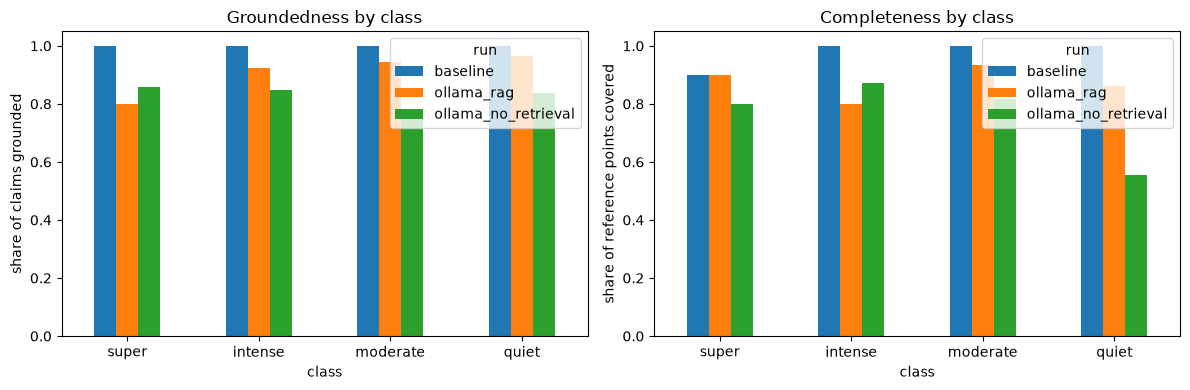

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
runs_shown = ["baseline", "ollama_rag", "ollama_no_retrieval"]
tab[runs_shown].plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0, 1.05); ax[0].set_title("Groundedness by class"); ax[0].set_ylabel("share of claims grounded")
tab2[runs_shown].plot.bar(ax=ax[1], rot=0); ax[1].set_ylim(0, 1.05); ax[1].set_title("Completeness by class"); ax[1].set_ylabel("share of reference points covered")
plt.tight_layout(); plt.savefig("../reports/figures/evaluation_groundedness_completeness.png", dpi=150, bbox_inches="tight"); plt.show()

## Per event (LLM with retrieval)

In [5]:
first[first["run"] == "ollama_rag"][["event_id", "class", "n_claims", "groundedness", "source_claims_grounded",
    "number_errors", "n_impacts", "completeness", "missed_points", "violations", "seconds"]].round(2)

,event_id,class,n_claims,groundedness,source_claims_grounded,number_errors,n_impacts,completeness,missed_points,violations,seconds
15,E002,moderate,8.0,1.00,1.00,0.0,0.0,1.00,,,84.4
16,E027,intense,6.0,1.00,1.00,0.0,0.0,0.80,kp_max,,65.2
17,E039,moderate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,158.8
18,E058,intense,6.0,1.00,1.00,0.0,0.0,0.83,kp_max,,151.5
19,E078,quiet,7.0,1.00,1.00,0.0,0.0,1.00,,,68.0
20,E095,moderate,7.0,1.00,1.00,0.0,0.0,1.00,,,70.0
21,E105,quiet,7.0,1.00,1.00,0.0,0.0,1.00,,,76.9
22,E117,moderate,6.0,0.83,1.00,0.0,0.0,0.80,kp_max,,72.3
23,E121,quiet,6.0,1.00,1.00,0.0,0.0,0.75,kp_max,,73.3
24,E143,quiet,6.0,1.00,1.00,0.0,0.0,0.80,kp_max,,73.2


## Why claims fail
Each row is one ungrounded claim from the LLM run with retrieval.

In [6]:
rag = cl[(cl["run"] == "ollama_rag") & (cl["repeat"] == 0)].copy()
def reason(r):
    out = []
    if not r["numbers_ok"]: out.append(f"number not in card/passages {r['bad_numbers']}")
    if r.get("no_cause") is False: out.append("cause from the card alone")
    if r.get("no_impact") is False: out.append("impact claim in a card-only section")
    if r.get("evidence_ok") is False: out.append("bad evidence path")
    if r.get("sources_ok") is False: out.append("missing/invalid source")
    if r.get("quiet_violation") is True: out.append("impact on a quiet window")
    if r["kind"] in ("interpretation", "impact") and r.get("judge_supported") is False: out.append("judge: not supported")
    if not r["no_forecast"]: out.append("forecast")
    return "; ".join(out)
bad = rag[~rag["grounded"]].assign(reason=lambda d: d.apply(reason, axis=1))
print(len(bad), "ungrounded of", len(rag), "claims")
print(bad["kind"].value_counts().to_dict())
bad[["event_id", "kind", "text", "reason"]]

8 ungrounded of 103 claims
{'summary': 3, 'impact': 3, 'interpretation': 2}


,event_id,kind,text,reason
270,E117,summary,"The storm was characterized by sustained southward Bz and high solar wind dynamic pressure, but no signifi...",impact claim in a card-only section
296,E216,summary,"The storm could have caused significant geoelectric fields and auroral displays, and may have impacted sat...",impact claim in a card-only section
303,E216,interpretation,Southward Bz is the main way solar wind energy enters the magnetosphere,judge: not supported
307,E216,impact,"Could disrupt HF radio communication, particularly on the dayside of the Earth",judge: not supported
314,E221,interpretation,"Ordinary solar wind speed and high solar activity suggest a calm space weather condition, with no signific...",judge: not supported
316,E231,summary,"The storm was associated with a sustained southward Bz of -19.1 nT and a high solar wind dynamic pressure,...",impact claim in a card-only section
321,E231,impact,"Could cause voltage control problems and protective system issues, potentially leading to grid collapse or...",
322,E231,impact,"Could cause extensive surface charging, problems with orientation, and disruptions in uplink/downlink and ...",


In [7]:
# judge reasons for the interpretation and impact claims it rejected
bad[bad["kind"].isin(["interpretation", "impact"])][["event_id", "text", "sources", "judge_reason"]]

,event_id,text,sources,judge_reason
303,E216,Southward Bz is the main way solar wind energy enters the magnetosphere,[d03_c004],The passages do not mention Southward Bz or solar wind energy entering the magnetosphere.
307,E216,"Could disrupt HF radio communication, particularly on the dayside of the Earth","[d14_c001, d14_c002]",[quote not found in passages] Passages describe HF radio communication disruption on the dayside.
314,E221,"Ordinary solar wind speed and high solar activity suggest a calm space weather condition, with no signific...",[d04_c003],"The passage indicates that high speed solar wind can bring geomagnetic storms, contradicting the claim of ..."
321,E231,"Could cause voltage control problems and protective system issues, potentially leading to grid collapse or...","[d03_c004, d01_c000]","Passages describe effects of G5 storms, which support G4 effects."
322,E231,"Could cause extensive surface charging, problems with orientation, and disruptions in uplink/downlink and ...","[d03_c004, d01_c000]","Directly states the effects for G5 storms, which are applicable to G4 storms."


## Retrieval versus no retrieval
The ablation gives the same model only the card. Without passages it cannot cite anything, so every cause or impact it writes is ungrounded.

In [8]:
cmp = first[first["run"].isin(["ollama_rag", "ollama_no_retrieval"])].pivot_table(
    index="run", values=["groundedness", "card_claims_grounded", "n_source_claims", "n_impacts", "completeness", "must_not_violations"], aggfunc="mean")
cmp.round(2)

,card_claims_grounded,completeness,groundedness,must_not_violations,n_impacts,n_source_claims
run,,,,,,
ollama_no_retrieval,1.00,0.75,0.83,0.0,0.0,1.2
ollama_rag,0.96,0.86,0.94,0.0,0.5,1.5


## Consistency (5 events x 3 runs, temperature 0.7)

In [9]:
res.get("consistency")

,run,event_id,class,runs,summary_similarity,evidence_jaccard,source_jaccard,groundedness_mean,groundedness_range,completeness_range,n_impacts
0,ollama_consistency,E039,moderate,3,0.951833,0.733333,0.366667,0.916667,0.250000,0.166667,0/0/2
1,ollama_consistency,E105,quiet,3,0.923700,0.714286,1.000000,1.000000,0.000000,0.000000,0/0/0
2,ollama_consistency,E158,intense,3,0.881699,0.426190,0.288889,0.878788,0.363636,0.285714,0/4/0
3,ollama_consistency,E216,super,3,0.863791,0.714286,0.621212,0.772080,0.008547,0.100000,5/3/6
4,ollama_consistency,E221,quiet,3,0.886927,0.529762,0.333333,0.944444,0.166667,0.250000,0/0/0


## How much to trust the judge
Three checks on the support judge:
1. The baseline's interpretation and impact claims are sentences copied verbatim from the cited passage, so a reasonable judge should accept nearly all of them.
2. A manual audit of all 21 interpretation and impact claims in the main LLM run (`evaluation/annotations/judge_audit_ollama_rag.csv`, labelled by reading the cited passages; drafted by the coding assistant, to be reviewed by me).
3. v1 versus v2. v1 only gave a verdict and accepted support that was not in the passages and G5 effects for a G4 storm. v2 must quote the supporting sentence (the quote is checked against the passages), and the code checks which NOAA G level that sentence sits under, because the small model ignored the level rule in its prompt.

In [10]:
from spacewx_rag.evaluation.judge import SupportJudge
base = cl[(cl["run"] == "baseline") & cl["kind"].isin(["interpretation", "impact"])]
print("1) baseline verbatim claims accepted:", int(base["judge_supported"].sum()), "of", len(base))

audit = pd.read_csv(P.eval_dir / "annotations" / "judge_audit_ollama_rag.csv")
r = cl[(cl["run"] == "ollama_rag") & cl["kind"].isin(["interpretation", "impact"])].reset_index(drop=True)
r["key"] = r["event_id"] + "|" + r["kind"]; audit["key"] = audit["event_id"] + "|" + audit["kind"]
r["n"] = r.groupby("key").cumcount(); audit["n"] = audit.groupby("key").cumcount()
m = r.merge(audit[["key", "n", "manual_supported", "note"]], on=["key", "n"])
assert all(t.startswith(s[:30]) for t, s in zip(m["text"], audit.set_index(["key", "n"]).loc[list(zip(m["key"], m["n"])), "claim_start"]))

# v1 verdicts from the cache, for the same claims and citations
v1 = SupportJudge(version="v1")
g = {e: c["geomagnetic"]["noaa_g_level_approx"] for e, c in __import__("spacewx_rag.cards", fromlist=["x"]).load_cards().items()}
chunks = pd.read_json(P.chunks, lines=True).set_index("chunk_id")
def v1_verdict(row):
    claim = row["text"] if row["kind"] == "interpretation" else f"For a geomagnetic storm at about NOAA {g[row['event_id']] or 'below G1'} level: {row['text']}"
    ps = [{"chunk_id": s, "text": chunks.loc[s, "text"]} for s in (row["sources"] if isinstance(row["sources"], list) else eval(row["sources"]))]
    d = v1.cache.get(v1.key(claim, ps))
    return None if d is None else d["supported"]
m["judge_v1"] = m.apply(v1_verdict, axis=1)
m["judge_v2"] = m["judge_supported"].astype(bool)
m["v2_plus_level"] = m["judge_v2"] & m["level_ok"].fillna(True).astype(bool)
rows = []
for col in ["judge_v1", "judge_v2", "v2_plus_level"]:
    x = m.dropna(subset=[col])
    acc = x[col].astype(bool)
    rows.append({"judge": col, "claims": len(x), "agree with manual": int((acc == x["manual_supported"]).sum()),
                 "false accepts": int((acc & ~x["manual_supported"]).sum()), "false rejects": int((~acc & x["manual_supported"]).sum())})
print("2-3) against the manual audit"); display(pd.DataFrame(rows))
m.loc[m["v2_plus_level"] != m["manual_supported"], ["event_id", "text", "judge_reason", "note"]]

1) baseline verbatim claims accepted: 70 of 70
2-3) against the manual audit


,judge,claims,agree with manual,false accepts,false rejects
0,judge_v1,21,16,5,0
1,judge_v2,21,17,4,0
2,v2_plus_level,21,19,2,0


,event_id,text,judge_reason,note
5,E105,"Southward Bz is the main way solar wind energy enters the magnetosphere, but the quiet Dst suggests that t...",Passages explain the concept of southward Bz.,second half ('quiet Dst suggests the energy was not sufficient') is an inference no passage makes
15,E216,"Could cause beautiful auroral displays, visible up to 55° latitude",Matches the claim about auroral visibility up to 55° latitude.,d12_c109's 55 degrees is an auroral elevation angle seen by camera in Namibia not a latitude


In [11]:
# groundedness of the main run if the manual labels replace the judge for these 21 claims
rc = cl[(cl["run"] == "ollama_rag") & (cl["repeat"] == 0)].copy()
rc["grounded_audited"] = rc["grounded"]
src = rc["kind"].isin(["interpretation", "impact"])
manual = m.set_index(["key", "n"])["manual_supported"]
rc.loc[src, "key"] = rc.loc[src, "event_id"] + "|" + rc.loc[src, "kind"]
rc.loc[src, "n"] = rc[src].groupby("key").cumcount()
for i, row in rc[src].iterrows():
    other = all([row["numbers_ok"], row["no_forecast"], row.get("sources_ok", True) is not False])
    rc.loc[i, "grounded_audited"] = other and bool(manual.loc[(row["key"], int(row["n"]))])
per = rc.groupby("event_id")[["grounded", "grounded_audited"]].mean()
print(f"main run groundedness, mean over 14 valid outputs: automatic {per['grounded'].mean():.3f} | with the manual audit {per['grounded_audited'].mean():.3f}")
print(f"claims pooled: automatic {rc['grounded'].mean():.3f} ({int(rc['grounded'].sum())}/{len(rc)}) | audited {rc['grounded_audited'].mean():.3f}")

main run groundedness, mean over 14 valid outputs: automatic 0.935 | with the manual audit 0.920
claims pooled: automatic 0.922 (95/103) | audited 0.903


## Retrieval relevance (42 labelled questions)

In [12]:
res["retrieval_summary"]

,questions,hit@1,hit@3,hit@5,MRR
extended_2026_11_17,24.0,0.792,0.958,0.958,0.854
original_18,18.0,0.778,1.000,1.000,0.889
all,42.0,0.786,0.976,0.976,0.869


In [13]:
rq = res["retrieval"]
rq[rq["rank"] != 1][["set", "question", "relevant", "retrieved", "rank"]]

,set,question,relevant,retrieved,rank
0,original_18,What Kp value corresponds to a severe G4 geomagnetic storm?,"[1, 2]","[9, 1, 9, 3, 1]",2.0
6,original_18,What are high-speed solar wind streams from coronal holes?,"[6, 3]","[4, 6, 6, 6, 6]",2.0
8,original_18,How does a geomagnetic storm affect satellite drag?,[15],"[3, 15, 3, 7, 18]",2.0
13,original_18,How does the solar wind transfer energy into the magnetosphere?,"[18, 3, 4]","[11, 18, 4, 18, 18]",2.0
18,extended_2026_11_17,At what Kp value does a minor G1 storm begin?,"[1, 2]","[20, 20, 1, 9, 1]",3.0
19,extended_2026_11_17,Which power grid effects are expected during an extreme G5 storm?,"[1, 2]","[7, 7, 7, 7, 7]",NaN
24,extended_2026_11_17,How do solar flares cause HF radio blackouts on the sunlit side of Earth?,[14],"[1, 2, 14, 2, 14]",3.0
29,extended_2026_11_17,How long does Kyoto take to replace provisional Dst with final Dst?,[21],"[20, 21, 20, 21, 21]",2.0
40,extended_2026_11_17,What does the NOAA S-scale for solar radiation storms describe?,"[1, 2]","[3, 5, 1, 20, 2]",3.0


### 07 evaluation findings

Main run (`ollama_rag`, 14 valid outputs, 103 claims):
- **Groundedness 0.935** (mean per output) or 0.922 pooled (95 of 103 claims). Replacing the judge with my manual labels for the 21 cause and impact claims gives **0.920** (0.903 pooled). The judge is lenient, so the audited figure is the one to quote.
- Card-based claims (summary sentences and characteristics) are grounded 96%: no number errors, no causes stated from the card. All failures are impact language in the summary.
- Cause and impact claims are grounded 86% (automatic). Failures: a wrong citation (E216), a flare mechanism given for a storm (E216 HF radio), an inference no passage makes (E221), and G5 effects for a G4 storm (E231, twice).
- **Completeness 0.86** of the reference points. The most-missed point is Kp or the G level (missed in 7 of 14). No must-not violations: no forecasts, no claims of observed damage, no unsourced causes in the summary, no storm language or impacts for quiet windows.
- By class: quiet 0.97 groundedness, moderate 0.94, intense 0.92, super 0.80. The more cause and impact claims an event gets, the more chances to fail (E216 has 15 claims, 5 of them impacts).

Retrieval versus no retrieval (same model, card only):
- Groundedness 0.94 with retrieval against 0.83 without. Without passages the card-based claims are fine (1.00) but every physics line has no source; completeness drops from 0.86 to 0.75, and to 0.55 for quiet windows.

Offline baseline: groundedness 1.00 and completeness 0.99, by construction (it copies card hints and passage sentences). This shows the metrics measure support, not usefulness: the baseline's copied impact sentences are sometimes off-topic and its text is stilted.

Consistency (5 events x 3 runs at temperature 0.7): summaries are similar (embedding cosine 0.86 to 0.95), the card fields cited overlap moderately (Jaccard 0.43 to 0.73), and the passages cited overlap less (0.29 to 1.0). The number of impacts varies between runs (E158: 0, 4, 0; E216: 5, 3, 6). Groundedness varies by up to 0.36 for E158. Quiet windows are the most stable.

The judge (same local model): it accepted all 70 verbatim baseline claims. Against the manual audit of 21 claims, v1 agreed on 16 (5 false accepts), v2 with a required quote on 17, and v2 plus the code-based G-level check on 19 (2 false accepts, 0 false rejects). The small model ignored the level rule in its prompt, which is why that check is in code. Groundedness from this judge is an upper bound.

Retrieval relevance, 42 labelled questions: hit@1 0.79, hit@3 0.98, MRR 0.87. On the 24 new questions, labelled before retrieval was run (an independent estimate): hit@1 0.79, hit@3 0.96. The one miss (G5 power-grid effects) returns the power-grid impact page five times instead of the NOAA scales, which also explains why G-level-specific effects are hard to get right at generation time.

Limits: 15 events (one super storm), one generator model, the judge is the same model, the reference points and the judge audit were drafted by the coding assistant and still need my review, and the consistency run covers five events.